In [178]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

In [179]:
def synthetic_data(w,b,num_examples):
    x = torch.normal(0,1,(num_examples,len(w)))
    y = torch.matmul(x,w)+b
    y += torch.normal(0,0.01,y.shape)
    return x,y

In [180]:
true_w = torch.tensor([2,-3.4])
true_b = 4.2
features,labels = synthetic_data(true_w,true_b,1000)

In [181]:
print('features:',features[0],'labels:',labels[0])

features: tensor([-0.9990,  0.8344]) labels: tensor(-0.6328)


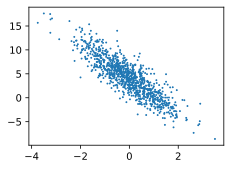

In [182]:
#w[1] = -3.4 , 因此呈现负相关
d2l.set_figsize()
d2l.plt.scatter(features[:,1].detach().numpy(),
    labels.detach().numpy(),1);

In [183]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))
    # 这些样本是随机读取的，没有特定的顺序
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i: min(i + batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]

In [184]:
batch_size = 10
for x,y in data_iter(batch_size,features,labels):
    print(x,'\n',y)
    break

tensor([[-0.4000,  0.9657],
        [-1.4939,  1.8042],
        [-1.4833,  0.6814],
        [ 1.1353, -3.2405],
        [-0.1733,  2.8174],
        [-0.0430, -0.3517],
        [-0.9343, -1.1981],
        [ 0.8905, -0.2160],
        [-0.8432, -1.1951],
        [-1.5093,  0.3851]]) 
 tensor([ 0.1181, -4.9382, -1.0823, 17.4904, -5.7429,  5.3181,  6.4185,  6.6914,
         6.5802, -0.1259])


In [185]:
w = torch.normal(0,0.01,size = (2,1),requires_grad = True)
b = torch.zeros(1,requires_grad = True)
display(w)
display(b)

tensor([[-0.0037],
        [ 0.0183]], requires_grad=True)

tensor([0.], requires_grad=True)

In [186]:
def linreg(x,w,b):
    return torch.matmul(x,w) + b

In [187]:
def squared_loss(y_hat,y):
    return (y_hat - y.reshape(y_hat.shape))**2/2

In [188]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size 
            param.grad.zero_()

In [196]:
lr = 0.01
num_epochs = 10
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for x,y in data_iter(batch_size,features,labels):
        l = loss(net(x,w,b),y)
        l.sum().backward()
        sgd([w,b],lr,batch_size)
    with torch.no_grad():
        train_l = loss(net(features,w,b),labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

epoch 1, loss 0.000051
epoch 2, loss 0.000051
epoch 3, loss 0.000051
epoch 4, loss 0.000051
epoch 5, loss 0.000051
epoch 6, loss 0.000051
epoch 7, loss 0.000051
epoch 8, loss 0.000051
epoch 9, loss 0.000051
epoch 10, loss 0.000051


In [197]:
print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差: {true_b - b}')

w的估计误差: tensor([-0.0004,  0.0003], grad_fn=<SubBackward0>)
b的估计误差: tensor([0.0009], grad_fn=<RsubBackward1>)
